# MandiMitra: Exploratory Data Analysis

## Objectives
- Analyse historical price trends across vegetables.
- Compare prices across states, districts and markets.
- Identify seasonal price patterns.
- Measure price volatility.
- Investigate unusual price movements.

In [1]:
# Imports and project setup

from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project directories
ROOT = Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw" / "parquet"
PROCESSED_DIR = ROOT / "data" / "processed"

# Check source files
RAW_FILES = sorted(RAW_DIR.glob("*.parquet"))

print("Project root:", ROOT)
print("Raw data directory:", RAW_DIR)
print("Number of Parquet files:", len(RAW_FILES))

# Create DuckDB connection
eda_con = duckdb.connect()

# Create a view over the original data
eda_con.execute(f"""
    CREATE VIEW raw_data AS
    SELECT *
    FROM read_parquet(
        '{RAW_DIR.as_posix()}/*.parquet',
        union_by_name = true
    )
""")

print("\nDuckDB connection ready.")

Project root: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra
Raw data directory: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\raw\parquet
Number of Parquet files: 26

DuckDB connection ready.


## 1. Prepare the Vegetable Analysis Dataset

Load the confirmed vegetable commodities from the original Parquet files.
Remove exact duplicate records, standardise dates and retain valid positive modal prices.

In [2]:
# Confirmed vegetable commodities from Notebook 3

confirmed_vegetables = [
    "Potato", "Onion", "Tomato", "Brinjal", "Green Chilli",
    "Cauliflower", "Bhindi (Ladies Finger)", "Cabbage",
    "Bottle gourd", "Bitter gourd", "Pumpkin", "Carrot",
    "Ginger (Green)", "Garlic", "Capsicum", "Spinach",
    "Beetroot", "Peas Wet", "Drumstick", "Cowpea (Veg)",
    "Pointed gourd (Parval)", "Amaranthus",
    "French Beans (Frasbean)", "Beans", "Cluster beans",
    "Methi (Leaves)", "Elephant Yam (Suran)", "Tapioca",
    "Onion Green", "Tinda", "Sweet Potato", "Green Peas",
    "Sweet Pumpkin", "Sponge gourd", "Mint (Pudina)",
    "Indian Beans (Seam)", "Yam (Ratalu)",
    "Cowpea (Lobia/Karamani)", "Turnip",
    "Surat Beans (Papadi)", "Bunch Beans", "White Pumpkin",
    "Yam", "Duster Beans",
    "Elephant Yam (Suran)/Amorphophallus",
    "Rat Tail Radish (Mogari)"
]

# Safely prepare SQL commodity list
vegetable_sql = ", ".join(
    "'" + name.replace("'", "''") + "'"
    for name in confirmed_vegetables
)

# Create cleaned vegetable analysis view
eda_con.execute(f"""
    CREATE OR REPLACE VIEW vegetable_prices AS

    SELECT DISTINCT
        TRIM(State) AS State,
        TRIM(District) AS District,
        TRIM(Market) AS Market,
        TRIM(Commodity) AS Commodity,
        TRIM(Variety) AS Variety,
        TRIM(Grade) AS Grade,

        TRY_CAST(Arrival_Date AS DATE) AS Arrival_Date,

        TRY_CAST(Min_Price AS DOUBLE) AS Min_Price,
        TRY_CAST(Max_Price AS DOUBLE) AS Max_Price,
        TRY_CAST(Modal_Price AS DOUBLE) AS Modal_Price

    FROM raw_data

    WHERE TRIM(Commodity) IN ({vegetable_sql})
      AND TRY_CAST(Arrival_Date AS DATE) IS NOT NULL
      AND TRY_CAST(Modal_Price AS DOUBLE) IS NOT NULL
      AND ISFINITE(TRY_CAST(Modal_Price AS DOUBLE))
      AND TRY_CAST(Modal_Price AS DOUBLE) > 0
""")

# Summarise the prepared dataset
vegetable_summary = eda_con.execute("""
    SELECT
        Commodity,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT State) AS States,
        COUNT(DISTINCT State || '|' || District || '|' || Market)
            AS Markets,
        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date

    FROM vegetable_prices

    GROUP BY Commodity
    ORDER BY Total_Records DESC
""").df()

display(vegetable_summary)

print("Total records:", eda_con.execute(
    "SELECT COUNT(*) FROM vegetable_prices"
).fetchone()[0])

print("Vegetables included:", len(vegetable_summary))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Total_Records,States,Markets,First_Date,Last_Date
0,Potato,3248774,33,2990,2001-01-10,2026-04-20
1,Onion,3168401,32,3223,2001-01-10,2026-04-20
2,Tomato,2818498,32,3075,2001-02-08,2026-04-20
3,Brinjal,2448357,31,2897,2001-01-27,2026-04-20
4,Green Chilli,2107918,31,2834,2001-03-12,2026-04-20
5,Cauliflower,1701542,33,2397,2001-01-27,2026-04-20
6,Bhindi (Ladies Finger),1571994,31,2493,2001-04-08,2026-04-20
7,Cabbage,1505826,33,2572,2001-11-22,2026-04-20
8,Bottle gourd,1214983,31,2083,2001-04-12,2026-04-20
9,Bitter gourd,1181866,32,2389,2001-04-21,2026-04-20


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total records: 30336319
Vegetables included: 46


## 2. Historical Reporting Coverage

Examine monthly record volumes and the number of reporting markets
across the vegetable dataset.

This helps identify changes in data availability and possible
reporting interruptions before interpreting historical price trends.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Month,Total_Records,Active_Markets
289,2025-02-01,280201,1462
290,2025-03-01,297032,1464
291,2025-04-01,292751,1461
292,2025-05-01,298784,1485
293,2025-06-01,281684,1483
294,2025-07-01,284346,1475
295,2025-08-01,273050,1483
296,2025-09-01,265453,1452
297,2025-10-01,184975,1430
298,2025-11-01,16450,1510


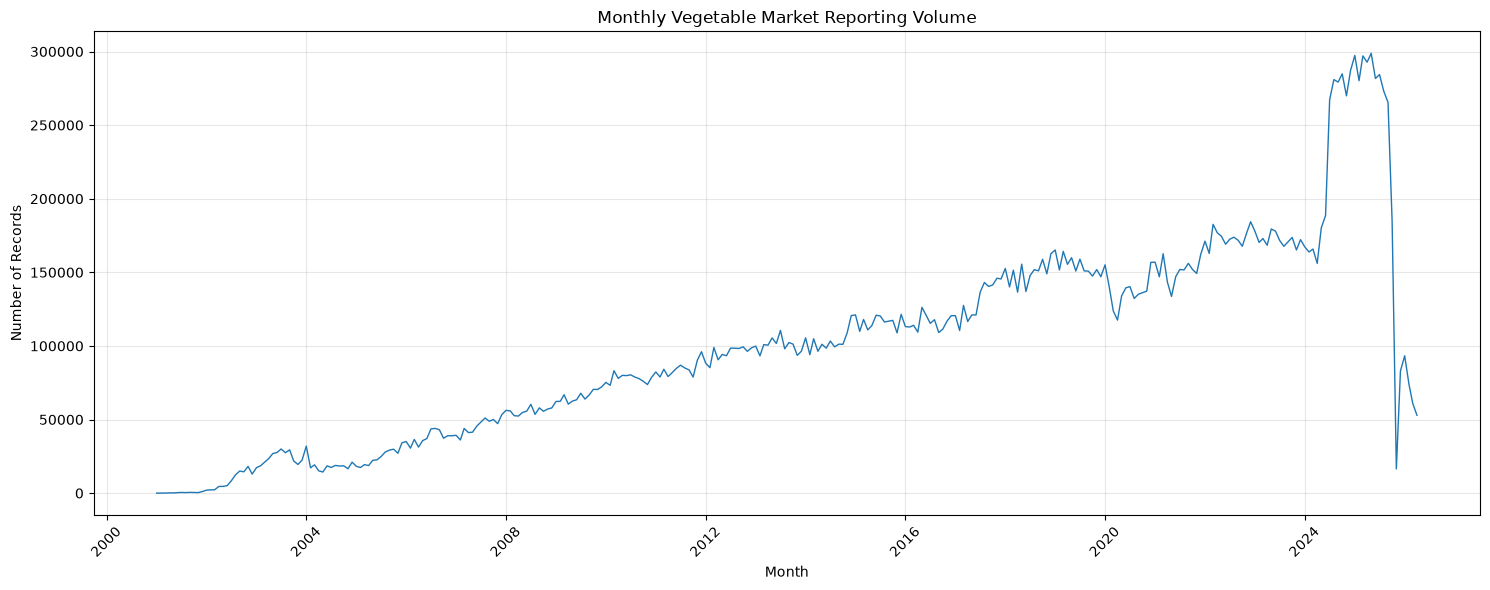

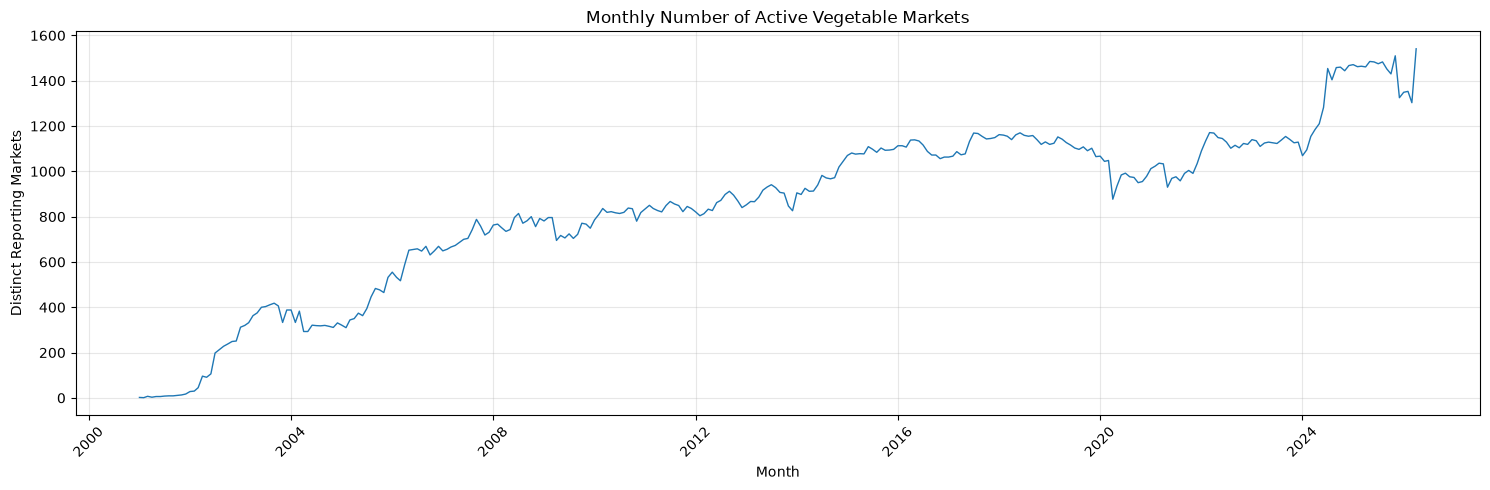

In [3]:
# Monthly reporting coverage across all confirmed vegetables

monthly_coverage = eda_con.execute("""
    SELECT
        DATE_TRUNC('month', Arrival_Date) AS Month,
        COUNT(*) AS Total_Records,

        COUNT(DISTINCT
            State || '|' || District || '|' || Market
        ) AS Active_Markets

    FROM vegetable_prices

    GROUP BY Month
    ORDER BY Month
""").df()

monthly_coverage["Month"] = pd.to_datetime(
    monthly_coverage["Month"]
)

display(monthly_coverage.tail(15))

# Plot monthly record volume
fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    monthly_coverage["Month"],
    monthly_coverage["Total_Records"],
    linewidth=1
)

ax1.set_title(
    "Monthly Vegetable Market Reporting Volume"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of Records")
ax1.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot active market coverage
plt.figure(figsize=(15, 5))

plt.plot(
    monthly_coverage["Month"],
    monthly_coverage["Active_Markets"],
    linewidth=1
)

plt.title("Monthly Number of Active Vegetable Markets")
plt.xlabel("Month")
plt.ylabel("Distinct Reporting Markets")
plt.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Commodity-wise Reporting Trends

Compare monthly reporting volumes across vegetables to identify
commodities with substantial reporting interruptions or recovery.

In [4]:
# Monthly reporting volume by commodity

commodity_monthly = eda_con.execute("""
    SELECT
        DATE_TRUNC('month', Arrival_Date) AS Month,
        Commodity,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT
            State || '|' || District || '|' || Market
        ) AS Active_Markets

    FROM vegetable_prices

    GROUP BY Month, Commodity
    ORDER BY Month, Commodity
""").df()

commodity_monthly["Month"] = pd.to_datetime(
    commodity_monthly["Month"]
)

# Compare October and November 2025
reporting_comparison = (
    commodity_monthly[
        commodity_monthly["Month"].isin([
            pd.Timestamp("2025-10-01"),
            pd.Timestamp("2025-11-01")
        ])
    ]
    .pivot(
        index="Commodity",
        columns="Month",
        values="Total_Records"
    )
    .fillna(0)
)

reporting_comparison.columns = [
    "October_2025",
    "November_2025"
]

reporting_comparison["Change_Pct"] = (
    (
        reporting_comparison["November_2025"]
        - reporting_comparison["October_2025"]
    )
    / reporting_comparison["October_2025"].replace(0, np.nan)
) * 100

reporting_comparison = (
    reporting_comparison
    .sort_values("Change_Pct")
)

display(reporting_comparison.round(2))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,October_2025,November_2025,Change_Pct
Commodity,,,
Bunch Beans,21.0,1.0,-95.24
Surat Beans (Papadi),34.0,2.0,-94.12
Tinda,417.0,25.0,-94.00
Sponge gourd,947.0,61.0,-93.56
Cowpea (Lobia/Karamani),137.0,9.0,-93.43
Duster Beans,44.0,3.0,-93.18
Pointed gourd (Parval),1529.0,106.0,-93.07
Bhindi (Ladies Finger),11136.0,813.0,-92.70
Elephant Yam (Suran),2613.0,194.0,-92.58


## 4. Post-Disruption Reporting Recovery

Compare monthly reporting volumes before and after November 2025.

Measure the recovery relative to October 2025, using October as
the pre-disruption reference month.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_17940\217011729.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(overall_recovery.round(2))


,Month,Total_Records,Active_Markets,Records_vs_October_Pct
0,2025-09-01,265453,14089,143.51
1,2025-10-01,184975,13676,100.00
2,2025-11-01,16450,9660,8.89
3,2025-12-01,83002,11901,44.87
4,2026-01-01,93317,12031,50.45
5,2026-02-01,74134,11978,40.08
6,2026-03-01,60933,11586,32.94
7,2026-04-01,52878,15050,28.59


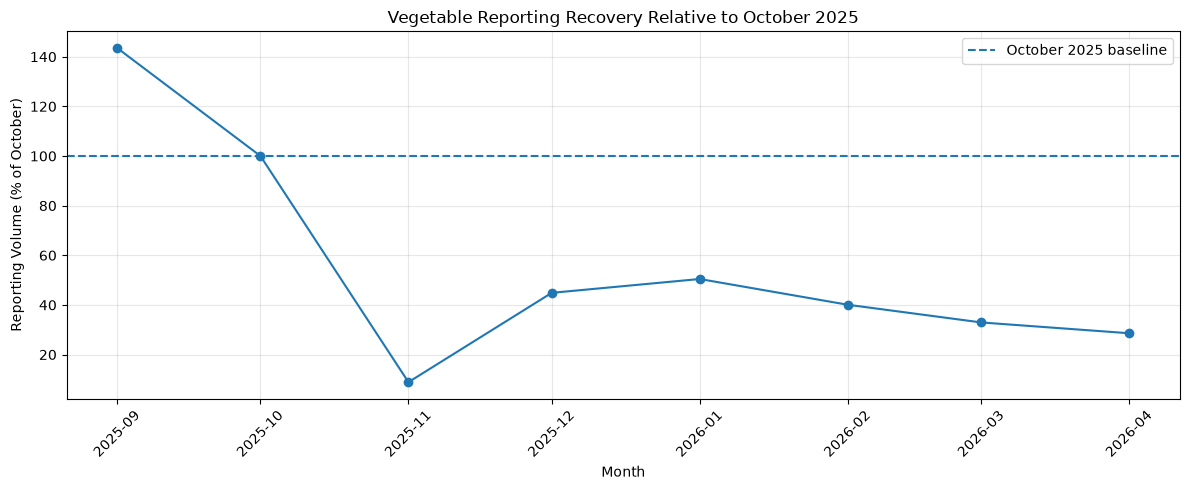

In [5]:
# Compare reporting volumes against October 2025

recovery_months = commodity_monthly[
    commodity_monthly["Month"] >= "2025-09-01"
].copy()

# Aggregate across all vegetables
overall_recovery = (
    recovery_months
    .groupby("Month", as_index=False)
    .agg(
        Total_Records=("Total_Records", "sum"),
        Active_Markets=("Active_Markets", "sum")
    )
)

# October 2025 is the reference month
october_records = overall_recovery.loc[
    overall_recovery["Month"] == "2025-10-01",
    "Total_Records"
].iloc[0]

overall_recovery["Records_vs_October_Pct"] = (
    overall_recovery["Total_Records"]
    / october_records
) * 100

display(overall_recovery.round(2))

# Plot recovery relative to October 2025
plt.figure(figsize=(12, 5))

plt.plot(
    overall_recovery["Month"],
    overall_recovery["Records_vs_October_Pct"],
    marker="o"
)

plt.axhline(
    100,
    linestyle="--",
    label="October 2025 baseline"
)

plt.title("Vegetable Reporting Recovery Relative to October 2025")
plt.xlabel("Month")
plt.ylabel("Reporting Volume (% of October)")
plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Historical Vegetable Price Trends

Analyse monthly modal price movements across vegetables.

Calculate monthly median prices for individual markets first,
then aggregate across markets to reduce the influence of
markets with higher reporting frequencies.

Prices are expressed in INR per quintal.

In [7]:
# Calculate monthly median prices for each market-variety-grade series

market_monthly_prices = eda_con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        DATE_TRUNC('month', Arrival_Date) AS Month,

        MEDIAN(Modal_Price) AS Median_Price,
        COUNT(*) AS Observations

    FROM vegetable_prices

    GROUP BY
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        Month
""").df()

market_monthly_prices["Month"] = pd.to_datetime(
    market_monthly_prices["Month"]
)

print(
    "Market-variety-grade-month observations:",
    len(market_monthly_prices)
)

display(market_monthly_prices.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Market-variety-grade-month observations: 2026810


,Commodity,State,District,Market,Variety,Grade,Month,Median_Price,Observations
0,Green Chilli,Andhra Pradesh,Kurnool,Kurnool,Other,FAQ,2003-01-01,1200.0,7
1,Bhindi (Ladies Finger),Telangana,Ranga Reddy,"Saroornagar,RBZ",Other,FAQ,2003-03-01,1000.0,9
2,Tomato,Andhra Pradesh,Krishna,"Bapulapadu,RBZ",Other,FAQ,2003-06-01,1000.0,18
3,Brinjal,Uttar Pradesh,Lalitpur,Lalitpur,Brinjal,FAQ,2003-06-01,680.0,19
4,Tapioca,Kerala,Kollam,Kollam,Other,FAQ,2003-07-01,485.0,8


In [8]:
# Stage 1: One price per market, commodity and month

market_monthly_summary = (
    market_monthly_prices
    .groupby(
        ["Commodity", "State", "District", "Market", "Month"],
        as_index=False
    )
    .agg(
        Market_Median_Price=("Median_Price", "median"),
        Series_Count=("Median_Price", "size"),
        Observations=("Observations", "sum")
    )
)

# Stage 2: Aggregate across markets for each commodity and month

commodity_monthly_trends = (
    market_monthly_summary
    .groupby(
        ["Commodity", "Month"],
        as_index=False
    )
    .agg(
        Median_Price=("Market_Median_Price", "median"),
        Lower_Quartile=(
            "Market_Median_Price",
            lambda x: x.quantile(0.25)
        ),
        Upper_Quartile=(
            "Market_Median_Price",
            lambda x: x.quantile(0.75)
        ),
        Active_Markets=("Market", "size")
    )
)

print(
    "Market-month observations:",
    len(market_monthly_summary)
)

print(
    "Commodity-month observations:",
    len(commodity_monthly_trends)
)

print("\nRecent monthly price indicators:")
display(
    commodity_monthly_trends[
        commodity_monthly_trends["Month"] >= "2025-01-01"
    ].tail(15).round(2)
)

Market-month observations: 1937648
Commodity-month observations: 12871

Recent monthly price indicators:


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_17940\1626278217.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(15).round(2)


,Commodity,Month,Median_Price,Lower_Quartile,Upper_Quartile,Active_Markets
12856,Yam (Ratalu),2025-02-01,6000.0,5000.0,7000.0,132
12857,Yam (Ratalu),2025-03-01,6500.0,4850.0,7500.0,126
12858,Yam (Ratalu),2025-04-01,7000.0,5200.0,8000.0,125
12859,Yam (Ratalu),2025-05-01,8000.0,5750.0,9000.0,113
12860,Yam (Ratalu),2025-06-01,8000.0,6000.0,11000.0,108
12861,Yam (Ratalu),2025-07-01,8000.0,6000.0,10000.0,113
12862,Yam (Ratalu),2025-08-01,8000.0,6000.0,9000.0,113
12863,Yam (Ratalu),2025-09-01,7000.0,6000.0,8000.0,126
12864,Yam (Ratalu),2025-10-01,6200.0,5350.0,7000.0,123
12865,Yam (Ratalu),2025-11-01,6000.0,4600.0,6750.0,121


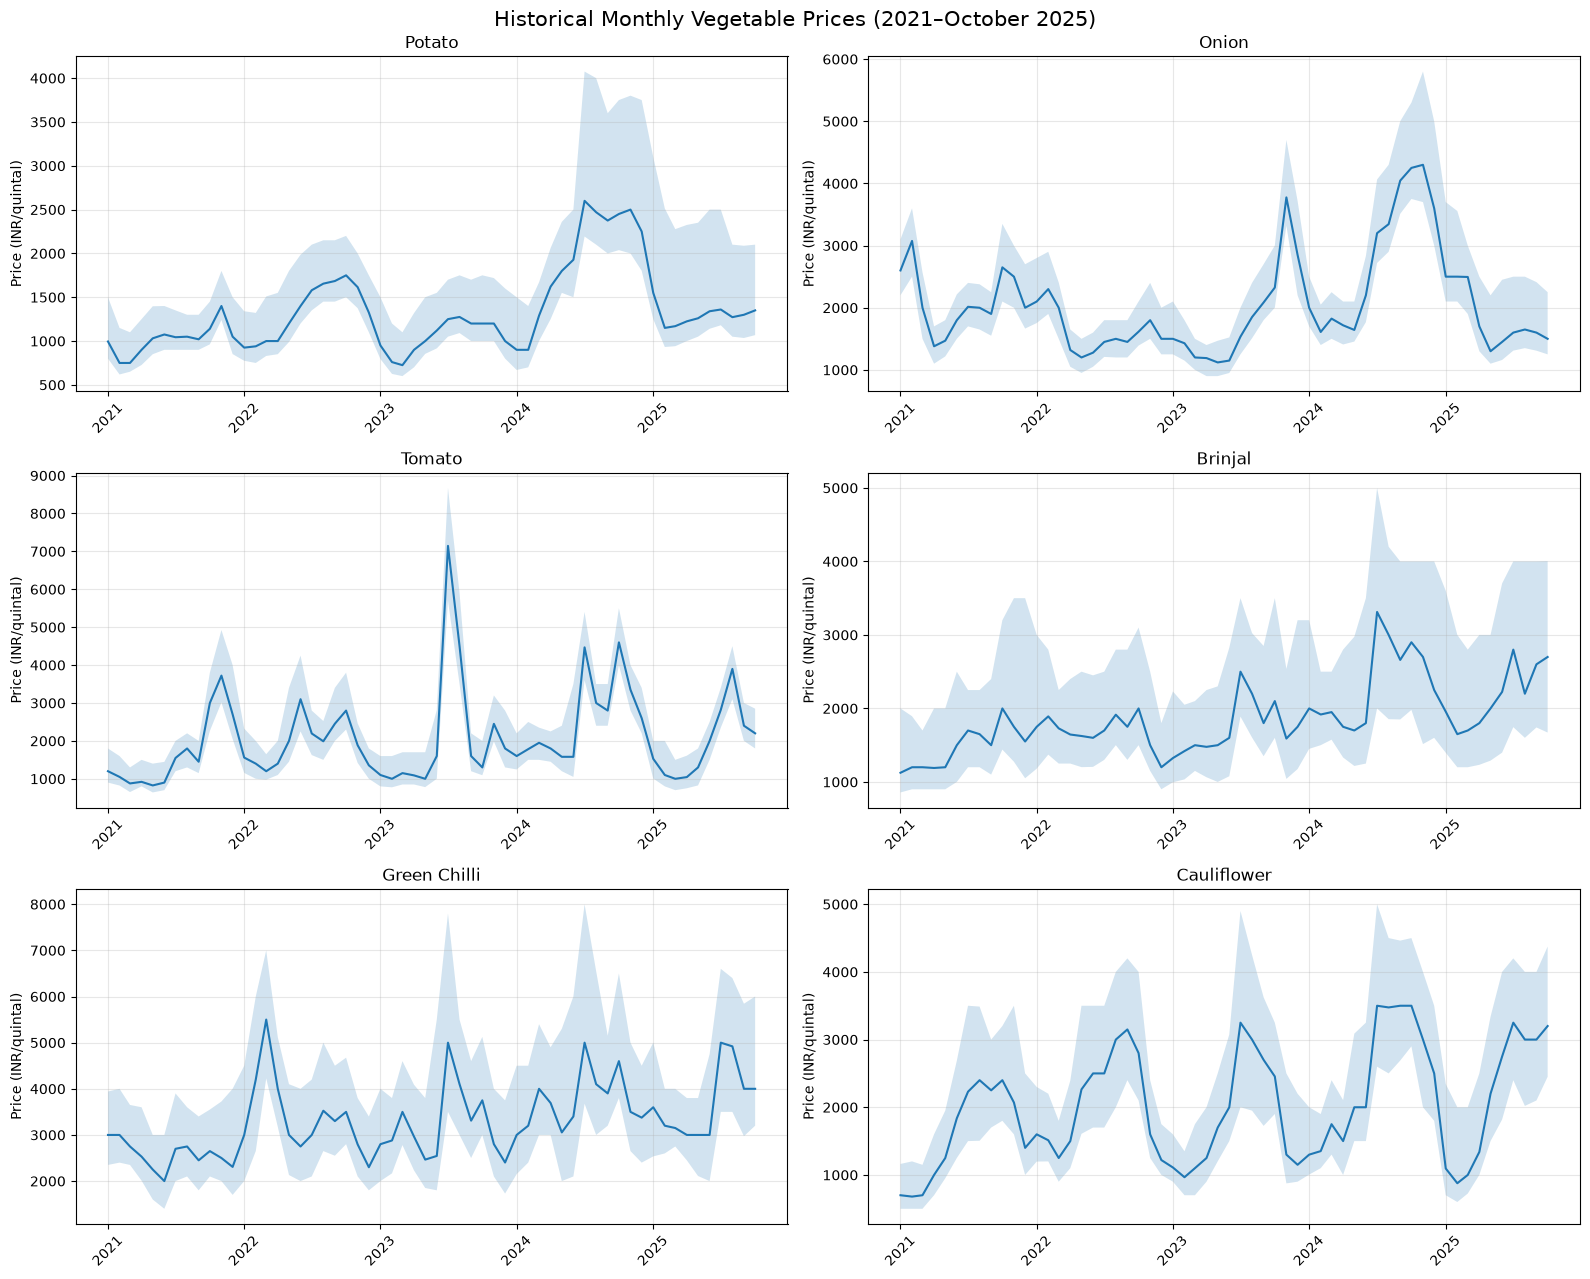

In [9]:
# Select six major vegetables for price trend analysis

selected_vegetables = [
    "Potato",
    "Onion",
    "Tomato",
    "Brinjal",
    "Green Chilli",
    "Cauliflower"
]

trend_data = commodity_monthly_trends[
    commodity_monthly_trends["Commodity"].isin(
        selected_vegetables
    )
    & (commodity_monthly_trends["Month"] >= "2021-01-01")
    & (commodity_monthly_trends["Month"] <= "2025-10-01")
].copy()

# Plot individual price trends

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 13)
)

for commodity, ax in zip(
    selected_vegetables,
    axes.flatten()
):
    subset = trend_data[
        trend_data["Commodity"] == commodity
    ]

    ax.plot(
        subset["Month"],
        subset["Median_Price"],
        linewidth=1.5,
        label="Median price"
    )

    ax.fill_between(
        subset["Month"],
        subset["Lower_Quartile"],
        subset["Upper_Quartile"],
        alpha=0.2,
        label="25th–75th percentile"
    )

    ax.set_title(commodity)
    ax.set_ylabel("Price (INR/quintal)")
    ax.grid(alpha=0.3)

    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "Historical Monthly Vegetable Prices (2021–October 2025)",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 6. Seasonal Price Patterns

Analyse how vegetable prices vary across calendar months.
Compare monthly median prices across multiple years to identify
recurring seasonal patterns.

In [12]:
# Calculate median price by commodity and calendar month

seasonal_prices = eda_con.execute("""
    SELECT
        Commodity,
        MONTH(Arrival_Date) AS Month_Number,
        MEDIAN(Modal_Price) AS Median_Price,
        COUNT(*) AS Observations,
        COUNT(DISTINCT YEAR(Arrival_Date)) AS Years_Covered
    FROM vegetable_prices
    WHERE Arrival_Date BETWEEN '2015-01-01' AND '2025-10-31'
    GROUP BY Commodity, Month_Number
    HAVING COUNT(DISTINCT YEAR(Arrival_Date)) >= 5
    ORDER BY Commodity, Month_Number
""").df()

display(seasonal_prices.head(24))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Month_Number,Median_Price,Observations,Years_Covered
0,Amaranthus,1,2600.0,17140,11
1,Amaranthus,2,2500.0,16411,11
2,Amaranthus,3,2500.0,17397,11
3,Amaranthus,4,2500.0,16203,11
4,Amaranthus,5,2500.0,17486,11
5,Amaranthus,6,2500.0,17591,11
6,Amaranthus,7,2500.0,20261,11
7,Amaranthus,8,2524.0,20628,11
8,Amaranthus,9,2500.0,20665,11
9,Amaranthus,10,2600.0,20216,11


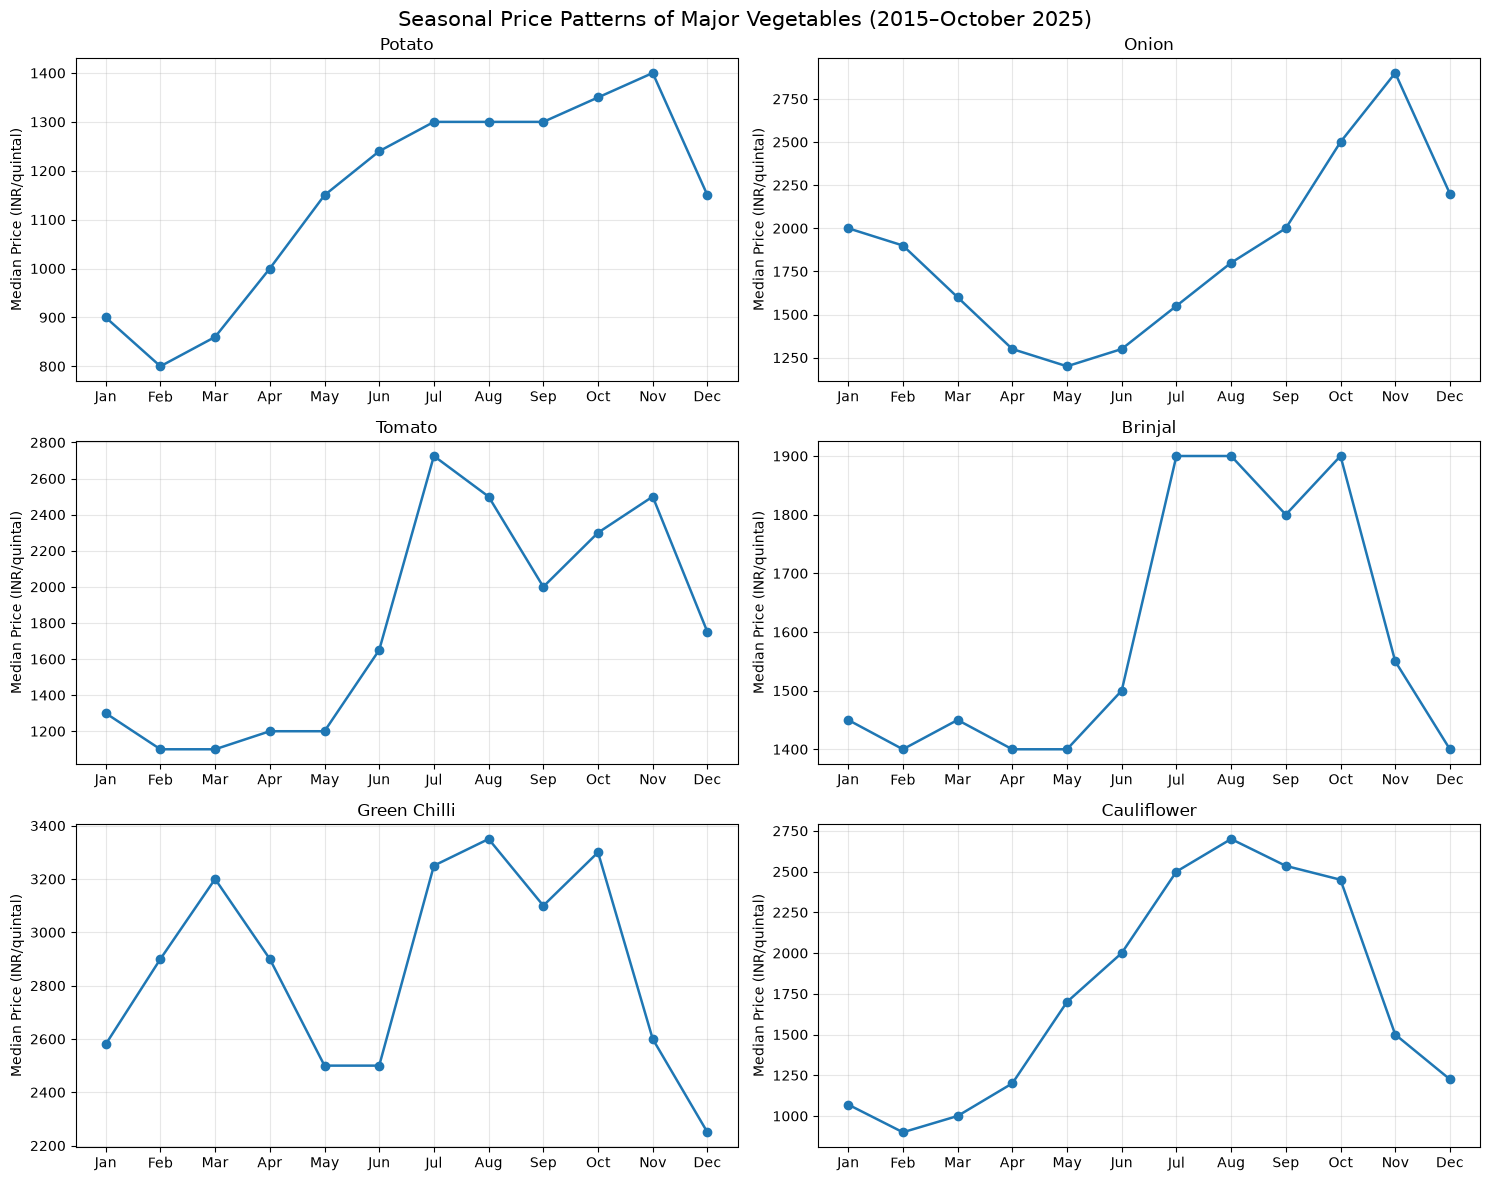

In [13]:
# Plot seasonal price patterns for six major vegetables

selected_vegetables = [
    "Potato", "Onion", "Tomato",
    "Brinjal", "Green Chilli", "Cauliflower"
]

seasonal_plot_data = seasonal_prices[
    seasonal_prices["Commodity"].isin(selected_vegetables)
].copy()

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for commodity, ax in zip(selected_vegetables, axes.flatten()):
    subset = seasonal_plot_data[
        seasonal_plot_data["Commodity"] == commodity
    ].sort_values("Month_Number")

    ax.plot(
        subset["Month_Number"],
        subset["Median_Price"],
        marker="o",
        linewidth=1.8
    )

    ax.set_title(commodity)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels)
    ax.set_ylabel("Median Price (INR/quintal)")
    ax.grid(alpha=0.3)

fig.suptitle(
    "Seasonal Price Patterns of Major Vegetables (2015–October 2025)",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [14]:
# Calculate monthly median prices separately for each year

yearly_monthly_prices = eda_con.execute("""
    SELECT
        Commodity,
        YEAR(Arrival_Date) AS Year,
        MONTH(Arrival_Date) AS Month_Number,
        MEDIAN(Modal_Price) AS Median_Price,
        COUNT(*) AS Observations
    FROM vegetable_prices
    WHERE Arrival_Date BETWEEN '2015-01-01' AND '2025-10-31'
    GROUP BY Commodity, Year, Month_Number
    HAVING COUNT(*) >= 100
    ORDER BY Commodity, Year, Month_Number
""").df()

# Summarise each calendar month's price across different years

seasonal_consistency = (
    yearly_monthly_prices
    .groupby(["Commodity", "Month_Number"], as_index=False)
    .agg(
        Typical_Price=("Median_Price", "median"),
        Lower_Quartile=("Median_Price", lambda x: x.quantile(0.25)),
        Upper_Quartile=("Median_Price", lambda x: x.quantile(0.75)),
        Years_Observed=("Year", "nunique")
    )
)

display(
    seasonal_consistency[
        seasonal_consistency["Commodity"].isin([
            "Potato", "Onion", "Tomato",
            "Brinjal", "Green Chilli", "Cauliflower"
        ])
    ]
    .sort_values(["Commodity", "Month_Number"])
    .round(2)
    .head(36)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,Month_Number,Typical_Price,Lower_Quartile,Upper_Quartile,Years_Observed
72,Brinjal,1,1200.0,1138.50,1650.0,11
73,Brinjal,2,1200.0,1050.00,1710.0,11
74,Brinjal,3,1200.0,1200.00,1600.0,11
75,Brinjal,4,1200.0,1150.00,1505.0,11
76,Brinjal,5,1200.0,1150.00,1560.0,11
77,Brinjal,6,1500.0,1275.00,1600.0,11
78,Brinjal,7,1700.0,1540.00,2250.0,11
79,Brinjal,8,1750.0,1637.50,2050.0,11
80,Brinjal,9,1750.0,1500.00,1820.0,11
81,Brinjal,10,1900.0,1498.75,2000.0,11


In [15]:
# Measure seasonal price variation for all vegetables

seasonal_variation = (
    seasonal_consistency
    .groupby("Commodity")
    .agg(
        Lowest_Month_Price=("Typical_Price", "min"),
        Highest_Month_Price=("Typical_Price", "max"),
        Average_Monthly_Price=("Typical_Price", "mean"),
        Minimum_Years_Observed=("Years_Observed", "min")
    )
    .reset_index()
)

seasonal_variation["Seasonal_Range"] = (
    seasonal_variation["Highest_Month_Price"]
    - seasonal_variation["Lowest_Month_Price"]
)

seasonal_variation["Seasonal_Variation_Pct"] = (
    seasonal_variation["Seasonal_Range"]
    / seasonal_variation["Average_Monthly_Price"]
) * 100

display(
    seasonal_variation
    .sort_values("Seasonal_Variation_Pct", ascending=False)
    .round(2)
    .head(20)
)

,Commodity,Lowest_Month_Price,Highest_Month_Price,Average_Monthly_Price,Minimum_Years_Observed,Seasonal_Range,Seasonal_Variation_Pct
39,Turnip,650.0,4500.0,2512.50,1,3850.0,153.23
15,Drumstick,2500.0,10000.0,5300.00,10,7500.0,141.51
27,Peas Wet,1900.0,7000.0,4129.17,10,5100.0,123.51
21,Green Peas,1930.0,7000.0,4219.17,10,5070.0,120.17
10,Carrot,900.0,3500.0,2261.67,10,2600.0,114.96
38,Tomato,1020.0,2800.0,1747.50,10,1780.0,101.86
11,Cauliflower,800.0,2500.0,1681.25,10,1700.0,101.12
40,White Pumpkin,405.0,1000.0,606.43,1,595.0,98.12
28,Pointed gourd (Parval),2372.5,5650.0,3411.88,10,3277.5,96.06
9,Capsicum,1500.0,4200.0,2828.00,10,2700.0,95.47


In [16]:
# Rank seasonal variation only for vegetables with adequate coverage

reliable_seasonal_variation = (
    seasonal_variation[
        seasonal_variation["Minimum_Years_Observed"] >= 8
    ]
    .sort_values(
        "Seasonal_Variation_Pct",
        ascending=False
    )
)

display(
    reliable_seasonal_variation[
        [
            "Commodity",
            "Lowest_Month_Price",
            "Highest_Month_Price",
            "Average_Monthly_Price",
            "Seasonal_Range",
            "Seasonal_Variation_Pct",
            "Minimum_Years_Observed"
        ]
    ]
    .round(2)
    .head(20)
)

,Commodity,Lowest_Month_Price,Highest_Month_Price,Average_Monthly_Price,Seasonal_Range,Seasonal_Variation_Pct,Minimum_Years_Observed
15,Drumstick,2500.0,10000.0,5300.00,7500.0,141.51,10
27,Peas Wet,1900.0,7000.0,4129.17,5100.0,123.51,10
21,Green Peas,1930.0,7000.0,4219.17,5070.0,120.17,10
10,Carrot,900.0,3500.0,2261.67,2600.0,114.96,10
38,Tomato,1020.0,2800.0,1747.50,1780.0,101.86,10
11,Cauliflower,800.0,2500.0,1681.25,1700.0,101.12,10
28,Pointed gourd (Parval),2372.5,5650.0,3411.88,3277.5,96.06,10
9,Capsicum,1500.0,4200.0,2828.00,2700.0,95.47,10
23,Methi (Leaves),875.0,2200.0,1445.33,1325.0,91.67,10
25,Onion,1140.0,2800.0,1817.75,1660.0,91.32,10


## 7. Price Volatility Analysis

Measure daily price fluctuations across vegetable market series.
Calculate daily percentage changes and summarise volatility
using the median absolute daily percentage change.

In [17]:
# Calculate daily price changes within individual market series

daily_price_changes = eda_con.execute("""
    WITH daily_prices AS (
        SELECT
            Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,
            Arrival_Date,
            MEDIAN(Modal_Price) AS Daily_Price
        FROM vegetable_prices
        WHERE Arrival_Date BETWEEN '2015-01-01' AND '2025-10-31'
        GROUP BY
            Commodity, State, District, Market,
            Variety, Grade, Arrival_Date
    ),

    price_changes AS (
        SELECT
            *,
            LAG(Daily_Price) OVER (
                PARTITION BY
                    Commodity, State, District,
                    Market, Variety, Grade
                ORDER BY Arrival_Date
            ) AS Previous_Price
        FROM daily_prices
    )

    SELECT
        Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        Arrival_Date,
        Daily_Price,
        Previous_Price,
        ABS(
            (Daily_Price - Previous_Price)
            / NULLIF(Previous_Price, 0)
        ) * 100 AS Absolute_Daily_Change_Pct
    FROM price_changes
    WHERE Previous_Price IS NOT NULL
""").df()

print("Daily price-change observations:", len(daily_price_changes))

display(daily_price_changes.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily price-change observations: 21021595


,Commodity,State,District,Market,Variety,Grade,Arrival_Date,Daily_Price,Previous_Price,Absolute_Daily_Change_Pct
0,Carrot,Gujarat,Surat,Surat,Other,FAQ,2022-08-12,3750.0,2375.0,57.894737
1,Carrot,Gujarat,Surat,Surat,Other,FAQ,2022-08-13,4250.0,3750.0,13.333333
2,Carrot,Gujarat,Surat,Surat,Other,FAQ,2022-08-17,2625.0,4250.0,38.235294
3,Carrot,Gujarat,Surat,Surat,Other,FAQ,2022-08-22,2875.0,2625.0,9.523810
4,Carrot,Gujarat,Surat,Surat,Other,FAQ,2022-08-23,2875.0,2875.0,0.000000


In [19]:
# Sort observations chronologically within each market series

series_columns = [
    "Commodity", "State", "District",
    "Market", "Variety", "Grade"
]

daily_price_changes = daily_price_changes.sort_values(
    series_columns + ["Arrival_Date"]
).copy()

# Calculate the previous reporting date

daily_price_changes["Previous_Date"] = (
    daily_price_changes
    .groupby(series_columns)["Arrival_Date"]
    .shift(1)
)

# Calculate days between reports

daily_price_changes["Days_Between_Reports"] = (
    daily_price_changes["Arrival_Date"]
    - daily_price_changes["Previous_Date"]
).dt.days

# Check the corrected intervals

print("Negative intervals:",
      (daily_price_changes["Days_Between_Reports"] < 0).sum())

print("\nReporting interval distribution:")

display(
    daily_price_changes["Days_Between_Reports"]
    .value_counts()
    .sort_index()
    .head(15)
)

Negative intervals: 0

Reporting interval distribution:


Days_Between_Reports
1.0     15603881
2.0      2839884
3.0      1014733
4.0       492364
5.0       239179
6.0       138901
7.0       188628
8.0        57946
9.0        41788
10.0       35682
11.0       29704
12.0       22359
13.0       19266
14.0       30044
15.0       12598
Name: count, dtype: int64

In [20]:
# Calculate volatility using reporting intervals of 1–3 days

short_interval_changes = daily_price_changes[
    daily_price_changes["Days_Between_Reports"].between(1, 3)
].copy()

# Summarise price volatility by commodity

volatility_summary = (
    short_interval_changes
    .groupby("Commodity")
    .agg(
        Price_Changes=("Absolute_Daily_Change_Pct", "count"),
        Median_Absolute_Change=(
            "Absolute_Daily_Change_Pct", "median"
        ),
        Average_Absolute_Change=(
            "Absolute_Daily_Change_Pct", "mean"
        ),
        P90_Absolute_Change=(
            "Absolute_Daily_Change_Pct",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
    .sort_values(
        "Median_Absolute_Change",
        ascending=False
    )
)

display(volatility_summary.round(2))

,Commodity,Price_Changes,Median_Absolute_Change,Average_Absolute_Change,P90_Absolute_Change
24,Methi (Leaves),108243,9.35,17.85,37.50
32,Rat Tail Radish (Mogari),1818,9.09,14.23,33.33
35,Surat Beans (Papadi),12471,8.70,14.86,32.76
39,Tinda,76518,6.67,13.08,33.33
1,Beans,155332,6.25,21.92,28.57
28,Peas Wet,200984,6.25,12.22,26.32
43,Yam,3962,5.88,10.78,27.78
18,French Beans (Frasbean),145304,5.88,10.86,26.92
16,Duster Beans,7649,5.26,11.26,28.57
33,Spinach,261725,5.00,16.46,33.33


In [21]:
# Examine extreme price movements by commodity

extreme_change_summary = (
    short_interval_changes
    .groupby("Commodity")
    .agg(
        Price_Changes=("Absolute_Daily_Change_Pct", "count"),
        Zero_Change_Pct=(
            "Absolute_Daily_Change_Pct",
            lambda x: (x == 0).mean() * 100
        ),
        Median_Change=(
            "Absolute_Daily_Change_Pct", "median"
        ),
        P95_Change=(
            "Absolute_Daily_Change_Pct",
            lambda x: x.quantile(0.95)
        ),
        P99_Change=(
            "Absolute_Daily_Change_Pct",
            lambda x: x.quantile(0.99)
        ),
        Maximum_Change=(
            "Absolute_Daily_Change_Pct", "max"
        ),
        Changes_Above_100_Pct=(
            "Absolute_Daily_Change_Pct",
            lambda x: (x > 100).sum()
        )
    )
    .reset_index()
    .sort_values("Maximum_Change", ascending=False)
)

display(extreme_change_summary.round(2))

,Commodity,Price_Changes,Zero_Change_Pct,Median_Change,P95_Change,P99_Change,Maximum_Change,Changes_Above_100_Pct
26,Onion,1844920,40.82,1.35,24.24,51.22,49599277.46,4396
1,Beans,155332,35.22,6.25,40.00,82.45,779900.00,894
4,Bitter gourd,792349,38.74,3.23,34.48,68.18,224900.00,2951
3,Bhindi (Ladies Finger),1035881,36.25,4.17,36.36,68.42,179900.00,3613
15,Drumstick,259868,43.88,3.70,38.46,83.53,166566.67,1598
19,Garlic,492556,34.32,0.85,30.77,75.92,166566.67,2770
8,Cabbage,968392,42.38,2.73,37.50,75.00,159900.00,4102
33,Spinach,261725,38.68,5.00,46.67,100.00,149900.00,1622
21,Green Chilli,1376802,34.42,2.73,33.33,66.67,142400.00,4868
38,Tapioca,127093,71.03,0.00,21.43,44.00,139900.00,160


In [22]:
# Inspect the largest observed price movements

largest_price_changes = (
    short_interval_changes
    .sort_values(
        "Absolute_Daily_Change_Pct",
        ascending=False
    )
    [[
        "Commodity",
        "State",
        "District",
        "Market",
        "Variety",
        "Grade",
        "Arrival_Date",
        "Days_Between_Reports",
        "Previous_Price",
        "Daily_Price",
        "Absolute_Daily_Change_Pct"
    ]]
    .head(30)
)

display(largest_price_changes.round(2))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_17940\1343243640.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(largest_price_changes.round(2))


,Commodity,State,District,Market,Variety,Grade,Arrival_Date,Days_Between_Reports,Previous_Price,Daily_Price,Absolute_Daily_Change_Pct
5731927,Onion,Maharashtra,Nashik,Kalvan,Red,FAQ,2024-12-23,3.0,1850.0,917588483.0,49599277.46
6504270,Beans,Karnataka,Mysore,Mysore (Bandipalya),Beans (Whole),FAQ,2024-04-15,1.0,1.0,7800.0,779900.00
8645002,Bitter gourd,Maharashtra,Sholapur,Pandharpur,Other,FAQ,2017-03-07,1.0,2.0,4500.0,224900.00
7053678,Bhindi (Ladies Finger),Odisha,Mayurbhanja,Udala,Bhindi,FAQ,2017-05-21,1.0,1.0,1800.0,179900.00
7053682,Bhindi (Ladies Finger),Odisha,Mayurbhanja,Udala,Bhindi,FAQ,2017-05-25,1.0,1.0,1800.0,179900.00
2606663,Onion,Uttar Pradesh,Maharajganj,Anandnagar,Red,FAQ,2015-01-26,2.0,1.0,1690.0,168900.00
13212325,Garlic,Kerala,Alappuzha,Chengannur,Other,FAQ,2018-06-12,3.0,3.0,5000.0,166566.67
10085222,Drumstick,Maharashtra,Sholapur,Pandharpur,Other,FAQ,2018-09-03,3.0,3.0,5000.0,166566.67
2606700,Onion,Uttar Pradesh,Maharajganj,Anandnagar,Red,FAQ,2015-03-23,1.0,1.0,1650.0,164900.00
18667228,Cabbage,Kerala,Kasargod,Manjeswaram,Cabbage,FAQ,2017-01-19,1.0,1.0,1600.0,159900.00


In [23]:
# Investigate price changes that start from unusually low prices

low_previous_price_summary = (
    short_interval_changes[
        short_interval_changes["Previous_Price"] <= 100
    ]
    .groupby("Commodity")
    .agg(
        Low_Base_Changes=("Previous_Price", "count"),
        Median_Previous_Price=("Previous_Price", "median"),
        Median_Current_Price=("Daily_Price", "median"),
        Maximum_Change_Pct=(
            "Absolute_Daily_Change_Pct", "max"
        )
    )
    .reset_index()
    .sort_values("Low_Base_Changes", ascending=False)
)

display(low_previous_price_summary.round(2))

print(
    "\nTotal transitions with previous price <= ₹100:",
    (short_interval_changes["Previous_Price"] <= 100).sum()
)

,Commodity,Low_Base_Changes,Median_Previous_Price,Median_Current_Price,Maximum_Change_Pct
28,Spinach,20105,6.0,6.0,149900.00
21,Methi (Leaves),11944,10.0,10.0,42400.00
24,Onion Green,11339,10.0,10.0,99900.00
22,Mint (Pudina),7575,4.0,4.0,139900.00
35,Tomato,3335,54.0,55.0,129900.00
7,Cabbage,2721,50.0,50.0,159900.00
6,Brinjal,2475,50.0,50.0,91900.00
23,Onion,2390,45.0,45.0,168900.00
5,Bottle gourd,2316,20.0,20.0,19900.00
10,Cauliflower,2144,50.0,55.0,24900.00



Total transitions with previous price <= ₹100: 87998


In [24]:
# Calculate absolute log price changes

short_interval_changes["Absolute_Log_Change_Pct"] = (
    np.abs(
        np.log(
            short_interval_changes["Daily_Price"]
            / short_interval_changes["Previous_Price"]
        )
    ) * 100
)

# Summarise robust volatility by commodity

log_volatility_summary = (
    short_interval_changes
    .groupby("Commodity")
    .agg(
        Price_Changes=("Absolute_Log_Change_Pct", "count"),
        Median_Log_Change=("Absolute_Log_Change_Pct", "median"),
        P90_Log_Change=(
            "Absolute_Log_Change_Pct",
            lambda x: x.quantile(0.90)
        ),
        P95_Log_Change=(
            "Absolute_Log_Change_Pct",
            lambda x: x.quantile(0.95)
        )
    )
    .reset_index()
    .sort_values("Median_Log_Change", ascending=False)
)

display(log_volatility_summary.round(2))

,Commodity,Price_Changes,Median_Log_Change,P90_Log_Change,P95_Log_Change
24,Methi (Leaves),108243,9.53,38.56,51.08
32,Rat Tail Radish (Mogari),1818,8.70,33.65,44.71
35,Surat Beans (Papadi),12471,8.70,32.98,45.18
39,Tinda,76518,6.90,32.85,45.68
1,Beans,155332,6.45,28.77,40.55
28,Peas Wet,200984,6.45,27.08,37.95
18,French Beans (Frasbean),145304,5.88,27.57,37.47
43,Yam,3962,5.72,28.77,40.55
16,Duster Beans,7649,5.22,28.77,40.55
33,Spinach,261725,4.88,33.65,45.20


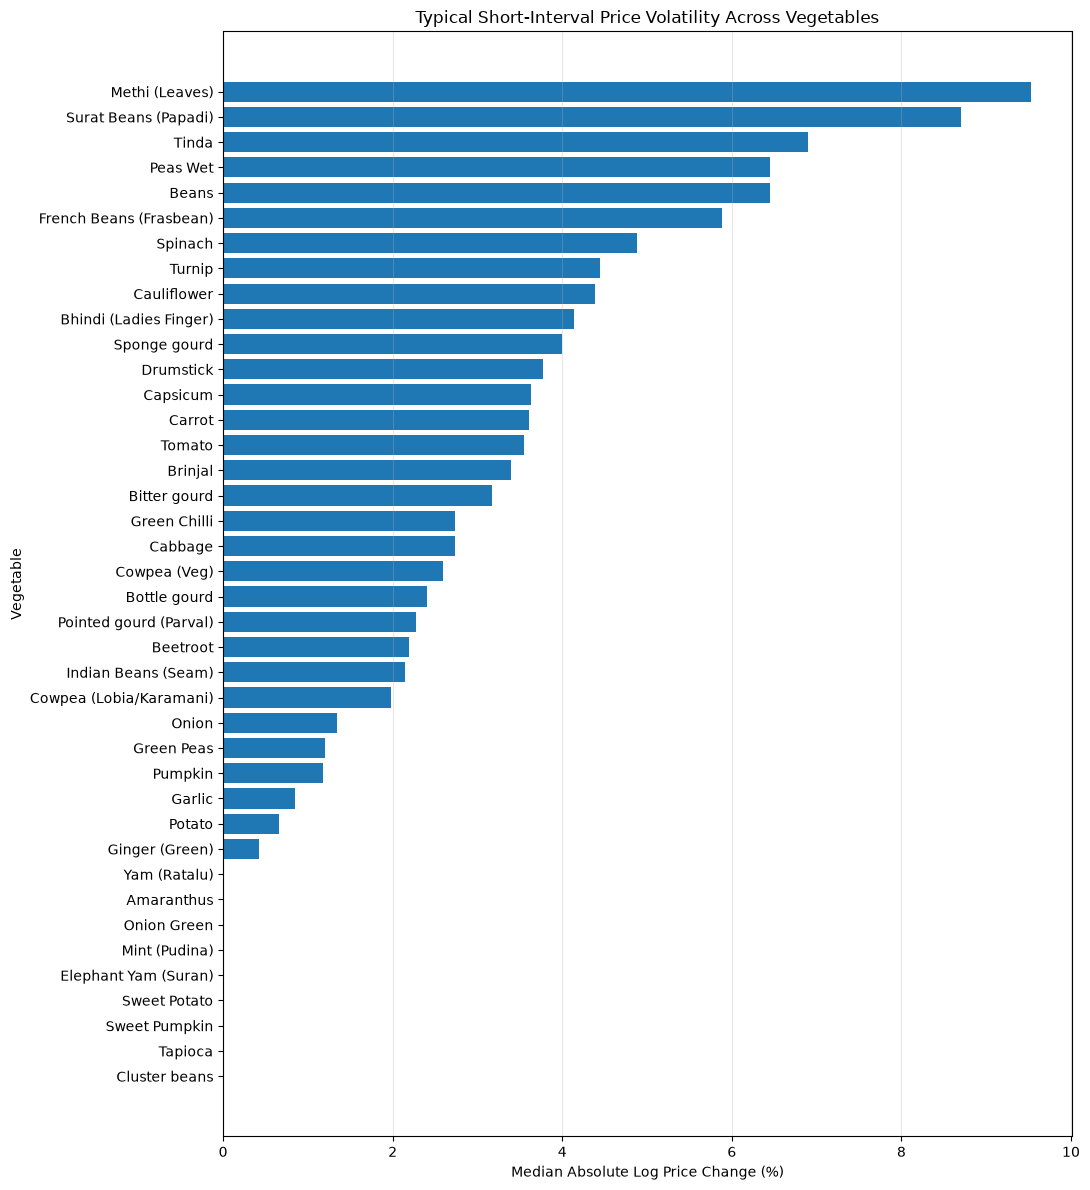

In [25]:
# Plot median log price changes by vegetable

volatility_plot_data = (
    log_volatility_summary[
        log_volatility_summary["Price_Changes"] >= 10000
    ]
    .sort_values("Median_Log_Change", ascending=True)
)

plt.figure(figsize=(11, 12))

plt.barh(
    volatility_plot_data["Commodity"],
    volatility_plot_data["Median_Log_Change"]
)

plt.xlabel("Median Absolute Log Price Change (%)")
plt.ylabel("Vegetable")
plt.title(
    "Typical Short-Interval Price Volatility Across Vegetables"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. State-wise Price Comparison

Compare median wholesale prices across Indian states for major vegetables.
Identify regional price differences while accounting for variation in
market coverage and reporting volume.

In [26]:
# Calculate state-wise median prices for major vegetables

major_vegetables = [
    "Potato", "Onion", "Tomato",
    "Brinjal", "Green Chilli", "Cauliflower"
]

state_price_comparison = eda_con.execute("""
    SELECT
        Commodity,
        State,
        MEDIAN(Modal_Price) AS Median_Price,
        COUNT(*) AS Observations,
        COUNT(DISTINCT District) AS Districts,
        COUNT(DISTINCT Market) AS Markets
    FROM vegetable_prices
    WHERE Commodity IN (
        'Potato', 'Onion', 'Tomato',
        'Brinjal', 'Green Chilli', 'Cauliflower'
    )
    AND Arrival_Date BETWEEN '2021-01-01' AND '2025-10-31'
    GROUP BY Commodity, State
    HAVING COUNT(*) >= 1000
    ORDER BY Commodity, Median_Price DESC
""").df()

display(state_price_comparison.round(2))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Commodity,State,Median_Price,Observations,Districts,Markets
0,Brinjal,Tamil Nadu,4000.0,69953,36,252
1,Brinjal,Meghalaya,3800.0,1651,7,13
2,Brinjal,Kerala,3500.0,91744,14,147
3,Brinjal,Nagaland,3500.0,2786,10,16
4,Brinjal,Tripura,3300.0,30025,8,32
...,...,...,...,...,...,...
136,Tomato,Rajasthan,1500.0,37927,33,52
137,Tomato,Maharashtra,1300.0,52038,18,64
138,Tomato,Uttrakhand,1300.0,17231,6,20
139,Tomato,Karnataka,1250.0,30730,20,52


In [27]:
# Compare high and low price states with stronger data coverage

reliable_state_comparison = state_price_comparison[
    (state_price_comparison["Observations"] >= 5000)
    & (state_price_comparison["Markets"] >= 5)
].copy()

state_price_extremes = pd.concat([
    reliable_state_comparison.groupby("Commodity")
    .head(5)
    .assign(Price_Group="Highest"),

    reliable_state_comparison.groupby("Commodity")
    .tail(5)
    .assign(Price_Group="Lowest")
]).sort_values(
    ["Commodity", "Price_Group", "Median_Price"],
    ascending=[True, True, False]
)

display(state_price_extremes.round(2))

,Commodity,State,Median_Price,Observations,Districts,Markets,Price_Group
0,Brinjal,Tamil Nadu,4000.0,69953,36,252,Highest
2,Brinjal,Kerala,3500.0,91744,14,147,Highest
4,Brinjal,Tripura,3300.0,30025,8,32,Highest
5,Brinjal,Odisha,3000.0,61619,27,83,Highest
6,Brinjal,West Bengal,2800.0,74314,21,56,Highest
16,Brinjal,Rajasthan,1500.0,10614,12,12,Lowest
19,Brinjal,Uttar Pradesh,1400.0,212292,74,206,Lowest
20,Brinjal,Haryana,1300.0,38906,21,71,Lowest
21,Brinjal,Uttrakhand,1000.0,13477,6,19,Lowest
22,Brinjal,Madhya Pradesh,950.0,30128,36,97,Lowest


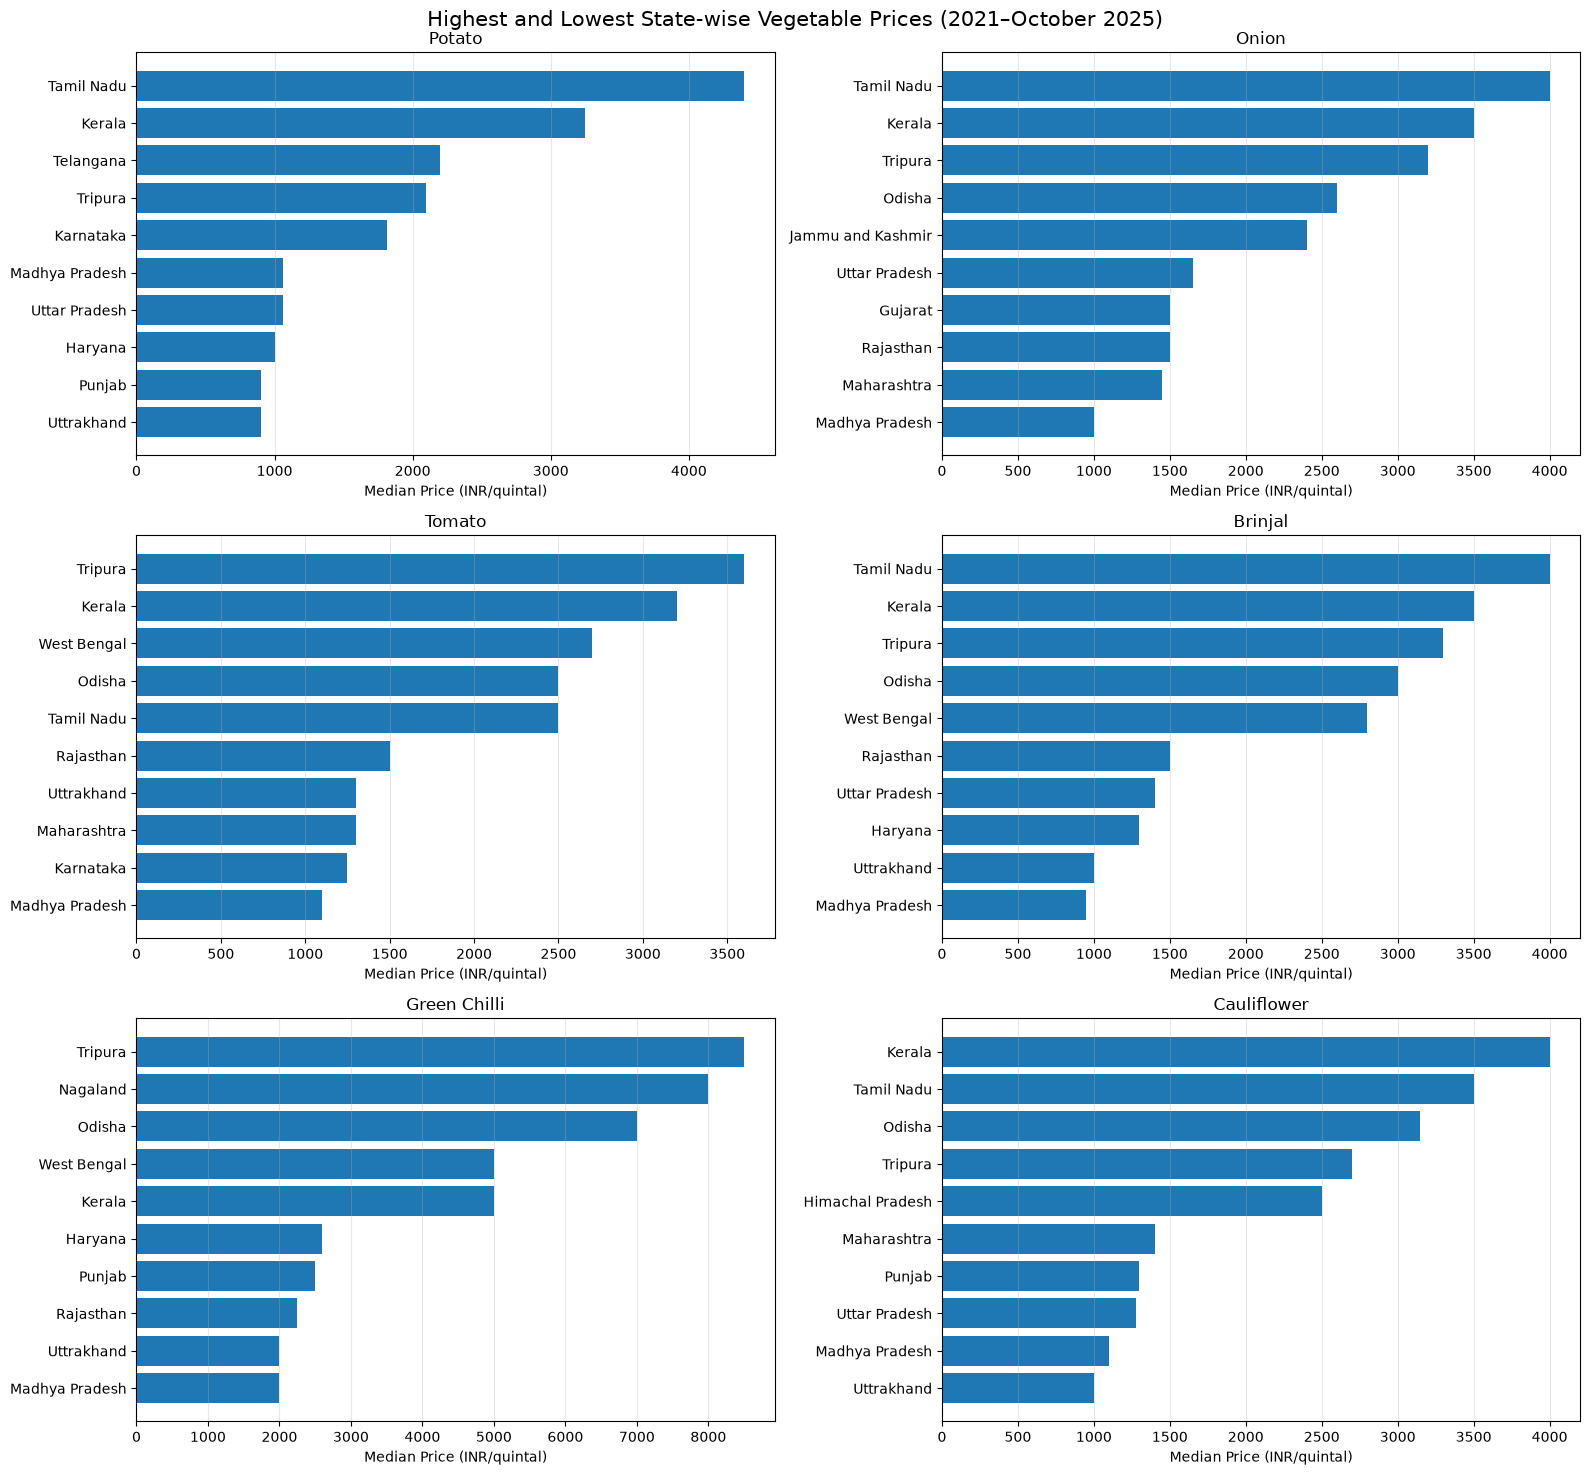

In [28]:
# Plot the five highest and lowest state medians for each vegetable

fig, axes = plt.subplots(3, 2, figsize=(16, 15))

for commodity, ax in zip(major_vegetables, axes.flatten()):

    subset = state_price_extremes[
        state_price_extremes["Commodity"] == commodity
    ].copy()

    subset = subset.sort_values("Median_Price")

    ax.barh(
        subset["State"],
        subset["Median_Price"]
    )

    ax.set_title(commodity)
    ax.set_xlabel("Median Price (INR/quintal)")
    ax.grid(axis="x", alpha=0.3)

fig.suptitle(
    "Highest and Lowest State-wise Vegetable Prices (2021–October 2025)",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [29]:
# Calculate market-wise median prices across India

national_market_prices = eda_con.execute("""
    SELECT
        Commodity,
        State,
        District,
        Market,
        MEDIAN(Modal_Price) AS Median_Price,
        COUNT(*) AS Observations,
        COUNT(DISTINCT YEAR(Arrival_Date)) AS Years_Covered
    FROM vegetable_prices
    WHERE Commodity IN (
        'Potato', 'Onion', 'Tomato',
        'Brinjal', 'Green Chilli', 'Cauliflower'
    )
      AND Arrival_Date BETWEEN '2021-01-01' AND '2025-10-31'
    GROUP BY Commodity, State, District, Market
    HAVING COUNT(*) >= 100
    ORDER BY Commodity, Median_Price DESC
""").df()

print("National market-level records:", len(national_market_prices))

display(national_market_prices.head(30).round(2))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

National market-level records: 6510


,Commodity,State,District,Market,Median_Price,Observations,Years_Covered
0,Brinjal,Kerala,Thiruvananthapuram,Pothencode,18040.0,818,4
1,Brinjal,Andaman and Nicobar,South Andaman,Port Blair,10000.0,133,3
2,Brinjal,Tamil Nadu,Dindigul,Dindigul (Uzhavar Sandhai ),8000.0,440,2
3,Brinjal,Tamil Nadu,Nagercoil (Kannyiakumari),Vadaseri,7000.0,475,2
4,Brinjal,Tamil Nadu,Dindigul,Chinnalapatti (Uzhavar Sandhai ),7000.0,366,2
5,Brinjal,Tamil Nadu,Nagercoil (Kannyiakumari),Myladi (Uzhavar Sandhai ),7000.0,163,1
6,Brinjal,Tamil Nadu,Pudukkottai,Pudukottai (Uzhavar Sandhai ),6000.0,443,2
7,Brinjal,Tamil Nadu,Ramanathapuram,Kamuthi (Uzhavar Sandhai ),6000.0,107,1
8,Brinjal,Tamil Nadu,Thirupur,Tiruppur (North) (Uzhavar Sandhai ),6000.0,362,2
9,Brinjal,Tamil Nadu,Pudukkottai,Alangudi (Uzhavar Sandhai ),6000.0,367,2


In [30]:
# Retain markets with stronger historical coverage

reliable_national_markets = national_market_prices[
    (national_market_prices["Observations"] >= 500)
    & (national_market_prices["Years_Covered"] >= 3)
].copy()

# Identify possible farmers' markets using market names
reliable_national_markets["Possible_Farmers_Market"] = (
    reliable_national_markets["Market"]
    .str.contains(
        r"uzhavar|sandhai|santhai|rythu bazar",
        case=False,
        na=False
    )
)

# Summarise coverage by vegetable
market_coverage_summary = (
    reliable_national_markets
    .groupby("Commodity")
    .agg(
        Eligible_Markets=("Market", "count"),
        States=("State", "nunique"),
        Median_Observations=("Observations", "median"),
        Farmers_Market_Count=("Possible_Farmers_Market", "sum")
    )
    .reset_index()
)

display(market_coverage_summary)

print(
    "\nTotal eligible market records:",
    len(reliable_national_markets)
)

,Commodity,Eligible_Markets,States,Median_Observations,Farmers_Market_Count
0,Brinjal,656,21,1120.0,7
1,Cauliflower,470,21,905.0,3
2,Green Chilli,584,23,1134.5,6
3,Onion,732,23,1159.0,2
4,Potato,738,25,1183.5,4
5,Tomato,716,21,1126.0,5



Total eligible market records: 3896


In [31]:
# Identify the five highest-priced and five lowest-priced
# eligible markets for each major vegetable

market_price_extremes = pd.concat([
    reliable_national_markets
    .sort_values("Median_Price", ascending=False)
    .groupby("Commodity")
    .head(5)
    .assign(Price_Group="Highest"),

    reliable_national_markets
    .sort_values("Median_Price", ascending=True)
    .groupby("Commodity")
    .head(5)
    .assign(Price_Group="Lowest")
])

market_price_extremes = market_price_extremes[
    [
        "Commodity", "Price_Group", "State",
        "District", "Market", "Median_Price",
        "Observations", "Years_Covered"
    ]
].sort_values(
    ["Commodity", "Price_Group", "Median_Price"],
    ascending=[True, True, False]
)

display(market_price_extremes.round(2))

,Commodity,Price_Group,State,District,Market,Median_Price,Observations,Years_Covered
0,Brinjal,Highest,Kerala,Thiruvananthapuram,Pothencode,18040.0,818,4
16,Brinjal,Highest,Telangana,Adilabad,Adilabad (Rythu Bazar),6000.0,586,5
17,Brinjal,Highest,Kerala,Thiruvananthapuram,Nedumangadu,5900.0,575,5
25,Brinjal,Highest,Kerala,Ernakulam,Thrippunithura,5200.0,1293,5
64,Brinjal,Highest,Kerala,Thiruvananthapuram,Parassala,4800.0,1604,5
1087,Brinjal,Lowest,Uttrakhand,UdhamSinghNagar,Kicchha,600.0,553,4
1085,Brinjal,Lowest,Uttrakhand,Haridwar,Bhagwanpur (Naveen Mandi Sthal),600.0,644,5
1090,Brinjal,Lowest,Madhya Pradesh,Dhar,Rajgarh,555.0,580,3
1092,Brinjal,Lowest,Uttar Pradesh,Muzaffarnagar,Shahpur,525.0,1037,5
1094,Brinjal,Lowest,Madhya Pradesh,Rajgarh,Narsinghgarh,300.0,674,3


In [32]:
# Investigate unusually high prices reported by Pothencode

pothencode_records = eda_con.execute("""
    SELECT
        Commodity,
        Arrival_Date,
        Variety,
        Grade,
        Min_Price,
        Max_Price,
        Modal_Price
    FROM vegetable_prices
    WHERE State = 'Kerala'
      AND Market = 'Pothencode'
      AND Commodity IN (
          'Potato', 'Onion', 'Tomato',
          'Brinjal', 'Green Chilli', 'Cauliflower'
      )
      AND Arrival_Date BETWEEN '2021-01-01' AND '2025-10-31'
    ORDER BY Commodity, Modal_Price DESC
""").df()

print("Pothencode records:", len(pothencode_records))

display(pothencode_records.head(30))

Pothencode records: 4523


,Commodity,Arrival_Date,Variety,Grade,Min_Price,Max_Price,Modal_Price
0,Brinjal,2024-01-20,Other,FAQ,55250.0,55300.0,55280.0
1,Brinjal,2023-12-27,Other,FAQ,48750.0,48800.0,48780.0
2,Brinjal,2023-12-23,Other,FAQ,48000.0,48080.0,48040.0
3,Brinjal,2023-12-25,Other,FAQ,48000.0,48070.0,48040.0
4,Brinjal,2023-12-30,Other,FAQ,45500.0,45580.0,45540.0
5,Brinjal,2023-12-29,Other,FAQ,45000.0,45080.0,45040.0
6,Brinjal,2023-12-28,Other,FAQ,45000.0,45080.0,45040.0
7,Brinjal,2023-12-26,Other,FAQ,44000.0,44080.0,44040.0
8,Brinjal,2024-07-10,Other,FAQ,42250.0,42300.0,42280.0
9,Brinjal,2024-07-17,Other,FAQ,42250.0,42300.0,42280.0


In [33]:
# Summarise price distributions at Pothencode

pothencode_summary = eda_con.execute("""
    SELECT
        Commodity,
        COUNT(*) AS Observations,
        MIN(Arrival_Date) AS First_Date,
        MAX(Arrival_Date) AS Last_Date,
        MEDIAN(Modal_Price) AS Median_Price,
        QUANTILE_CONT(Modal_Price, 0.25) AS Q1_Price,
        QUANTILE_CONT(Modal_Price, 0.75) AS Q3_Price,
        MAX(Modal_Price) AS Maximum_Price,
        COUNT(DISTINCT Variety) AS Varieties,
        COUNT(DISTINCT Grade) AS Grades
    FROM vegetable_prices
    WHERE State = 'Kerala'
      AND Market = 'Pothencode'
      AND Commodity IN (
          'Potato', 'Onion', 'Tomato',
          'Brinjal', 'Green Chilli', 'Cauliflower'
      )
      AND Arrival_Date BETWEEN '2021-01-01' AND '2025-10-31'
    GROUP BY Commodity
    ORDER BY Commodity
""").df()

display(pothencode_summary.round(2))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_17940\2333268581.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(pothencode_summary.round(2))


,Commodity,Observations,First_Date,Last_Date,Median_Price,Q1_Price,Q3_Price,Maximum_Price,Varieties,Grades
0,Brinjal,818,2021-01-02,2025-10-30,18040.0,4800.0,26440.0,55280.0,2,1
1,Cauliflower,808,2021-01-02,2025-10-24,22540.0,5530.0,36040.0,72040.0,2,1
2,Green Chilli,802,2021-01-02,2025-10-30,24040.0,5200.0,32540.0,110540.0,2,1
3,Onion,644,2021-01-02,2025-04-03,19540.0,10040.0,32665.0,58540.0,1,1
4,Potato,644,2021-01-02,2025-04-03,19280.0,13540.0,26040.0,39040.0,1,1
5,Tomato,807,2021-01-02,2025-10-31,20040.0,5000.0,29280.0,60040.0,2,1


In [34]:
# Compare Pothencode with other Kerala markets

kerala_market_comparison = eda_con.execute("""
    SELECT
        Commodity,
        Market,
        COUNT(*) AS Observations,
        MEDIAN(Modal_Price) AS Median_Price,
        QUANTILE_CONT(Modal_Price, 0.25) AS Q1_Price,
        QUANTILE_CONT(Modal_Price, 0.75) AS Q3_Price
    FROM vegetable_prices
    WHERE State = 'Kerala'
      AND Commodity IN (
          'Potato', 'Onion', 'Tomato',
          'Brinjal', 'Green Chilli', 'Cauliflower'
      )
      AND Arrival_Date BETWEEN '2021-01-01' AND '2025-10-31'
    GROUP BY Commodity, Market
    HAVING COUNT(*) >= 100
    ORDER BY Commodity, Median_Price DESC
""").df()

# Show the ten highest and ten lowest markets per commodity
kerala_market_extremes = pd.concat([
    kerala_market_comparison.groupby("Commodity").head(10),
    kerala_market_comparison.groupby("Commodity").tail(10)
]).drop_duplicates()

display(kerala_market_extremes.round(2))

,Commodity,Market,Observations,Median_Price,Q1_Price,Q3_Price
0,Brinjal,Pothencode,818,18040.0,4800.0,26440.0
1,Brinjal,Nedumangadu,575,5900.0,5600.0,7500.0
2,Brinjal,Omalloor,415,5700.0,5200.0,5800.0
3,Brinjal,Thrippunithura,1293,5200.0,4400.0,5700.0
4,Brinjal,Anyara (EEC),167,5100.0,4100.0,5600.0
...,...,...,...,...,...,...
440,Tomato,vadakarapathy,915,2000.0,1300.0,2900.0
441,Tomato,Thamarassery,1000,1850.0,1300.0,2625.0
442,Tomato,Palayam,1233,1714.0,1250.0,2678.0
443,Tomato,Thirurrangadi,1067,1400.0,1000.0,2400.0


In [35]:
# Compare Pothencode with other Kerala markets year by year

pothencode_yearly_comparison = eda_con.execute("""
    WITH market_year_prices AS (
        SELECT
            Commodity,
            Market,
            YEAR(Arrival_Date) AS Year,
            MEDIAN(Modal_Price) AS Median_Price
        FROM vegetable_prices
        WHERE State = 'Kerala'
          AND Commodity IN (
              'Potato', 'Onion', 'Tomato',
              'Brinjal', 'Green Chilli', 'Cauliflower'
          )
          AND Arrival_Date BETWEEN '2021-01-01' AND '2025-10-31'
        GROUP BY Commodity, Market, Year
        HAVING COUNT(*) >= 20
    )

    SELECT
        Commodity,
        Year,
        MAX(Median_Price) FILTER (
            WHERE Market = 'Pothencode'
        ) AS Pothencode_Median,
        MEDIAN(Median_Price) FILTER (
            WHERE Market != 'Pothencode'
        ) AS Other_Markets_Median,
        COUNT(*) FILTER (
            WHERE Market != 'Pothencode'
        ) AS Other_Markets
    FROM market_year_prices
    GROUP BY Commodity, Year
    HAVING COUNT(*) FILTER (
        WHERE Market = 'Pothencode'
    ) > 0
    ORDER BY Commodity, Year
""").df()

pothencode_yearly_comparison["Price_Ratio"] = (
    pothencode_yearly_comparison["Pothencode_Median"]
    / pothencode_yearly_comparison["Other_Markets_Median"]
)

display(pothencode_yearly_comparison.round(2))

,Commodity,Year,Pothencode_Median,Other_Markets_Median,Other_Markets,Price_Ratio
0,Brinjal,2021,4200.0,3000.0,80,1.40
1,Brinjal,2023,16540.0,3200.0,82,5.17
2,Brinjal,2024,26040.0,4000.0,100,6.51
3,Brinjal,2025,4800.0,3550.0,101,1.35
4,Cauliflower,2021,5600.0,3600.0,44,1.56
5,Cauliflower,2023,15040.0,3800.0,49,3.96
6,Cauliflower,2024,36040.0,4400.0,47,8.19
7,Cauliflower,2025,5000.0,4000.0,48,1.25
8,Green Chilli,2021,4900.0,3800.0,68,1.29
9,Green Chilli,2023,22540.0,4800.0,73,4.70


In [36]:
# Investigate price-ending patterns at Pothencode

pothencode_price_endings = eda_con.execute("""
    SELECT
        Commodity,
        YEAR(Arrival_Date) AS Year,
        CAST(Modal_Price AS BIGINT) % 1000 AS Last_Three_Digits,
        COUNT(*) AS Records
    FROM vegetable_prices
    WHERE State = 'Kerala'
      AND Market = 'Pothencode'
      AND Commodity IN (
          'Potato', 'Onion', 'Tomato',
          'Brinjal', 'Green Chilli', 'Cauliflower'
      )
      AND Arrival_Date BETWEEN '2021-01-01' AND '2025-10-31'
    GROUP BY Commodity, Year, Last_Three_Digits
    ORDER BY Commodity, Year, Records DESC
""").df()

display(
    pothencode_price_endings
    .groupby(["Year", "Last_Three_Digits"])["Records"]
    .sum()
    .reset_index()
    .sort_values(["Year", "Records"], ascending=[True, False])
    .groupby("Year")
    .head(8)
)

,Year,Last_Three_Digits,Records
2,2021,200,81
3,2021,300,62
8,2021,800,40
9,2021,900,38
6,2021,600,36
0,2021,0,25
7,2021,700,23
5,2021,500,17
11,2023,40,690
27,2023,540,215


In [37]:
# Verify Pothencode price patterns in the original source files

pothencode_raw_check = eda_con.execute(f"""
    SELECT
        YEAR(TRY_CAST(Arrival_Date AS DATE)) AS Year,
        COUNT(*) AS Records,
        MEDIAN(Modal_Price) AS Median_Price,
        COUNT(*) FILTER (
            WHERE CAST(Modal_Price AS BIGINT) % 1000 = 40
        ) AS Ending_040,
        COUNT(*) FILTER (
            WHERE CAST(Modal_Price AS BIGINT) % 1000 = 540
        ) AS Ending_540
    FROM raw_data
    WHERE TRIM(State) = 'Kerala'
      AND TRIM(Market) = 'Pothencode'
      AND TRIM(Commodity) IN (
          'Potato', 'Onion', 'Tomato',
          'Brinjal', 'Green Chilli', 'Cauliflower'
      )
      AND TRY_CAST(Arrival_Date AS DATE)
          BETWEEN DATE '2021-01-01' AND DATE '2025-10-31'
    GROUP BY Year
    ORDER BY Year
""").df()

display(pothencode_raw_check.round(2))

,Year,Records,Median_Price,Ending_040,Ending_540
0,2021,351,3600.0,0,0
1,2023,1327,15780.0,690,215
2,2024,1732,28840.0,863,353
3,2025,1113,5000.0,279,82


### Data Quality Finding: Pothencode Market

An investigation of Pothencode market prices identified unusually high reported
prices for all six major vegetables during 2023–2024.

The median price increased substantially compared with other Kerala markets.
The observations also showed unusual concentration in price endings such as
040 and 540.

The same patterns were confirmed in the original Parquet files, establishing
that the anomaly was present in the source dataset and was not introduced
during preprocessing.

**Treatment:**
- Original observations are retained without modification.
- Pothencode 2023–2024 observations are flagged for further verification.
- They are excluded from primary market-price rankings until independently
  validated.
- No assumed correction factor is applied.

The cause remains unverified. These observations should not be interpreted
as confirmed market prices for selling recommendations.